# Historical Global Development Analytics

**Goal:** investigate trends and regional gaps in life expectancy and GDP per capita in the 142-country Gapminder panel, 1952–2007. Observations are five years apart. Correlation is not causation.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.analytics import load_data, annual_summary, regional_summary, country_change, key_metrics
df = load_data(ROOT / "data" / "gapminder_1952_2007.csv")
print(f"Shape: {df.shape}; countries: {df.country.nunique()}; years: {df.year.nunique()}")
df.head()

Shape: (1704, 8); countries: 142; years: 12


,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
0,Afghanistan,Asia,1952,28.801,8425333,779.445314,AFG,4
1,Afghanistan,Asia,1957,30.332,9240934,820.853030,AFG,4
2,Afghanistan,Asia,1962,31.997,10267083,853.100710,AFG,4
3,Afghanistan,Asia,1967,34.020,11537966,836.197138,AFG,4
4,Afghanistan,Asia,1972,36.088,13079460,739.981106,AFG,4


## 1. Validate data quality
Check missing values, duplicate country-year keys and time coverage. The packaged historical dataset is already structured; do not claim extensive cleaning.

In [2]:
print("Missing values:\n",df.isna().sum())
print("Duplicate country-year rows:",df.duplicated(["country","year"]).sum())
print("Years:", sorted(df.year.unique()))

Missing values:
 country      0
continent    0
year         0
lifeExp      0
pop          0
gdpPercap    0
iso_alpha    0
iso_num      0
dtype: int64
Duplicate country-year rows: 0
Years: [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]


## 2. Build population-weighted KPIs
Population-weighting answers a different question than averaging country figures equally.

In [3]:
annual = annual_summary(df)
regional = regional_summary(df)
changes = country_change(df)
metrics = key_metrics(df, annual, regional)
print(metrics)
annual

{'source': 'Gapminder data bundled with Plotly (historical country-year panel)', 'first_year': 1952, 'last_year': 2007, 'rows': 1704, 'countries': 142, 'years_observed': 12, 'start_population_weighted_life_expectancy': 48.94, 'end_population_weighted_life_expectancy': 68.92, 'change_in_weighted_life_expectancy_years': 19.97, 'highest_region_in_last_year': 'Oceania', 'highest_region_weighted_life_expectancy': 81.06, 'lowest_region_in_last_year': 'Africa', 'lowest_region_weighted_life_expectancy': 54.56, 'cross_country_spearman_rho_last_year': 0.857, 'cross_country_spearman_p_last_year': 4.622974536298113e-42}


,year,countries,represented_population,weighted_life_expectancy,median_gdp_per_capita
0,1952,142,2406957150,48.944237,1968.528344
1,1957,142,2664404580,52.121885,2173.220291
2,1962,142,2899782974,52.324382,2335.439533
3,1967,142,3217478384,56.984307,2678.334741
4,1972,142,3576977158,59.514783,3339.129407
5,1977,142,3930045807,61.237256,3798.609244
6,1982,142,4289436840,62.881755,4216.228428
7,1987,142,4691477418,64.416350,4280.300366
8,1992,142,5110710260,65.645900,4386.085502
9,1997,142,5515204472,66.849343,4781.825478


## 3. Compare regions

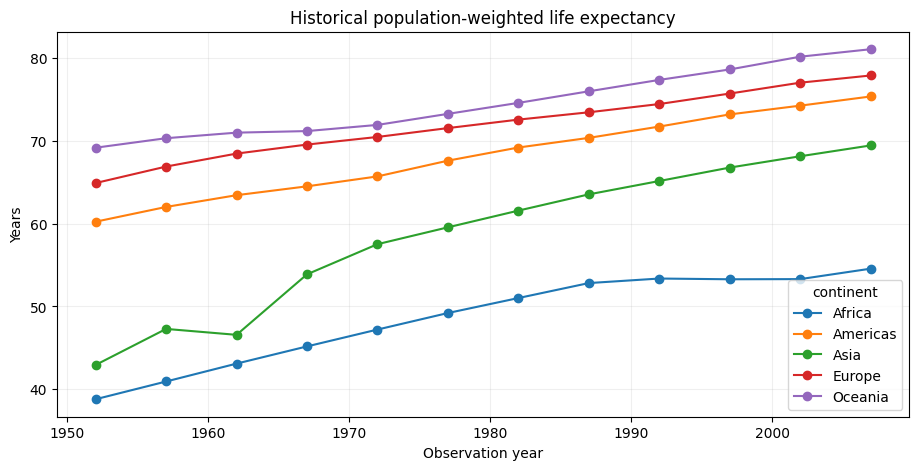

In [4]:
pivot = regional.pivot(index="year", columns="continent", values="weighted_life_expectancy")
ax=pivot.plot(figsize=(11,5), marker="o", title="Historical population-weighted life expectancy")
ax.set(ylabel="Years",xlabel="Observation year")
ax.grid(alpha=.2)
plt.show()

## 4. Explore country-level association in 2007
This is ecological, correlational analysis, not a causal model.

Spearman rho=0.857, p=4.6e-42 (exploratory only)


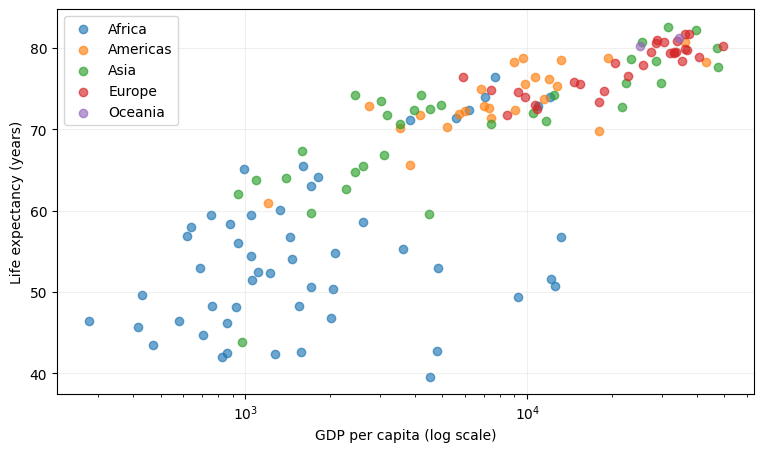

In [5]:
d2007=df[df.year==2007]
rho,p=spearmanr(d2007.gdpPercap,d2007.lifeExp)
print(f"Spearman rho={rho:.3f}, p={p:.2g} (exploratory only)")
fig,ax=plt.subplots(figsize=(9,5))
for label,group in d2007.groupby("continent"):
    ax.scatter(group.gdpPercap,group.lifeExp,alpha=.65,label=label)
ax.set_xscale("log");ax.set(xlabel="GDP per capita (log scale)",ylabel="Life expectancy (years)")
ax.legend();ax.grid(alpha=.18);plt.show()

## 5. Countries with the largest life expectancy changes
The outcome is a historical change between endpoint snapshots, not evidence of causality.

In [6]:
changes[["country","continent","life_expectancy_start","life_expectancy_end","life_expectancy_change_years"]].head(12)

,country,continent,life_expectancy_start,life_expectancy_end,life_expectancy_change_years
0,Oman,Asia,37.578,75.640,38.062
1,Vietnam,Asia,40.412,74.249,33.837
2,Indonesia,Asia,37.468,70.650,33.182
3,Saudi Arabia,Asia,39.875,72.777,32.902
4,Libya,Africa,42.723,73.952,31.229
5,"Korea, Rep.",Asia,47.453,78.623,31.170
6,Nicaragua,Americas,42.314,72.899,30.585
7,West Bank and Gaza,Asia,43.160,73.422,30.262
8,"Yemen, Rep.",Asia,32.548,62.698,30.150
9,Gambia,Africa,30.000,59.448,29.448


## 6. Compare SQL and Python KPI definitions

In [7]:
import sqlite3
with sqlite3.connect(ROOT / "data" / "development.sqlite") as con:
    sql_2007=pd.read_sql_query("SELECT SUM(lifeExp*pop)*1.0/SUM(pop) AS weighted_avg FROM country_year WHERE year=2007",con)
print("SQLite result:",sql_2007.iloc[0,0]," / Python result:",annual.loc[annual.year==2007,"weighted_life_expectancy"].iloc[0])

SQLite result: 68.91909251904042  / Python result: 68.91909251904043


## 7. Interpretation and limitations
- The 142-country panel is not complete global coverage.
- The last observation is **2007**, not a current statistic.
- Five-year country-year observations are not independent customer-level samples.
- Population-weighted statistics do not describe within-country inequality.
- Cross-country relationships cannot establish causal mechanisms.

**Next step:** Read `CASE_STUDY.md`, then customize the analytical question and add your own responsible interpretation.